In [41]:
%pip install "kagglehub[pandas-datasets]"
import kagglehub
from kagglehub import KaggleDatasetAdapter

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# web URE -> https://www.kaggle.com/datasets/mohammedarfathr/smartwatch-health-data-uncleaned
# Data set Name --> Smartwatch Health Data (Uncleaned)

import kagglehub
import pandas as pd
from pathlib import Path

path = kagglehub.dataset_download(
    "mohammedarfathr/smartwatch-health-data-uncleaned"
)

# Find all files
for file in Path(path).rglob("*"):
    if file.is_file():
        print(file)

# Load the CSV file automatically
file = list(Path(path).rglob("*.csv"))[0]

df = pd.read_csv(file)

df.head()

C:\Users\Admin\.cache\kagglehub\datasets\mohammedarfathr\smartwatch-health-data-uncleaned\versions\1\unclean_smartwatch_health_data.csv


,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
0,4174.0,58.939776,98.809650,5450.390578,7.167235622316564,Highly Active,1
1,NaN,NaN,98.532195,727.601610,6.538239375570314,Highly_Active,5
2,1860.0,247.803052,97.052954,2826.521994,ERROR,Highly Active,5
3,2294.0,40.000000,96.894213,13797.338044,7.367789630207228,Actve,3
4,2130.0,61.950165,98.583797,15679.067648,NaN,Highly_Active,6


In [43]:
df.head()

,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
0,4174.0,58.939776,98.809650,5450.390578,7.167235622316564,Highly Active,1
1,NaN,NaN,98.532195,727.601610,6.538239375570314,Highly_Active,5
2,1860.0,247.803052,97.052954,2826.521994,ERROR,Highly Active,5
3,2294.0,40.000000,96.894213,13797.338044,7.367789630207228,Actve,3
4,2130.0,61.950165,98.583797,15679.067648,NaN,Highly_Active,6


In [44]:
df.tail()

,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
9995,1524.0,78.819386,98.931927,2948.491953,7.402748595032027,Active,7
9996,4879.0,48.632659,95.773035,4725.623070,6.3821659358529015,Sedentary,2
9997,2624.0,73.834442,97.945874,2571.492060,6.91654920303435,Sedentary,4
9998,4907.0,NaN,98.401058,3364.788855,5.691233932149209,Active,8
9999,4113.0,70.063864,98.475606,544.696104,5.691001039740254,Actve,5


In [45]:
df.shape

(10000, 7)

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   User ID                 9799 non-null   float64
 1   Heart Rate (BPM)        9600 non-null   float64
 2   Blood Oxygen Level (%)  9700 non-null   float64
 3   Step Count              9900 non-null   float64
 4   Sleep Duration (hours)  9850 non-null   str    
 5   Activity Level          9800 non-null   str    
 6   Stress Level            9800 non-null   str    
dtypes: float64(4), str(3)
memory usage: 547.0 KB


In [47]:
df.describe()

,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count
count,9799.000000,9600.000000,9700.000000,9900.000000
mean,3007.480253,76.035462,97.841581,6985.685885
std,1150.581542,19.412483,1.732863,6885.809680
min,1001.000000,40.000000,90.791208,0.910138
25%,1997.500000,64.890152,96.662683,2021.039657
50%,2998.000000,75.220601,98.010642,4962.534599
75%,4004.000000,85.198249,99.376179,9724.902880
max,4999.000000,296.593970,100.000000,62486.690753


In [48]:
df.columns

Index(['User ID', 'Heart Rate (BPM)', 'Blood Oxygen Level (%)', 'Step Count',
       'Sleep Duration (hours)', 'Activity Level', 'Stress Level'],
      dtype='str')

In [49]:
df.dtypes

User ID                   float64
Heart Rate (BPM)          float64
Blood Oxygen Level (%)    float64
Step Count                float64
Sleep Duration (hours)        str
Activity Level                str
Stress Level                  str
dtype: object

In [50]:
df.isnull().sum()

User ID                   201
Heart Rate (BPM)          400
Blood Oxygen Level (%)    300
Step Count                100
Sleep Duration (hours)    150
Activity Level            200
Stress Level              200
dtype: int64

In [51]:
df.duplicated().sum()

np.int64(0)


# 1. Project workflow
## Steps For EDA
- Categorise the given column as a Numerical, Categorical, Mixed Data type column
- Univariate Analysis ---> Numerical Column or Categorical Column
- Numerical Column Analysis ---> Distribution of the Data ---> Histogram, kdeplot ----> Outliers ---> Boxplot ----> Handle Missing Values
- Categorical Column Analysis ---> Distribution of the Data ---> countplot ----> Missing Values
- Bivariate Analysis --> Numerical Numerical --> Scatterplot
- Numerical Categorical ---> barplot
- Categorical Categorical ---> Heatmap
- EDA ---> Feature Engineering

In [52]:
# %pip install kagglehub pandas numpy matplotlib seaborn scikit-learn

Then import the libraries and download your dataset.

In [53]:

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler

# Download dataset
path = kagglehub.dataset_download(
    "mohammedarfathr/smartwatch-health-data-uncleaned")

# Find and load CSV
csv_file = list(Path(path).rglob("*.csv"))[0]
df = pd.read_csv(csv_file)

# Keep the original data unchanged
df_original = df.copy()
print(df.head())

   User ID  Heart Rate (BPM)  Blood Oxygen Level (%)    Step Count  \
0   4174.0         58.939776               98.809650   5450.390578   
1      NaN               NaN               98.532195    727.601610   
2   1860.0        247.803052               97.052954   2826.521994   
3   2294.0         40.000000               96.894213  13797.338044   
4   2130.0         61.950165               98.583797  15679.067648   

  Sleep Duration (hours) Activity Level Stress Level  
0      7.167235622316564  Highly Active            1  
1      6.538239375570314  Highly_Active            5  
2                  ERROR  Highly Active            5  
3      7.367789630207228          Actve            3  
4                    NaN  Highly_Active            6  


# 3. Data understanding — EDA

Run these operations to understand the dataset before cleaning it.

In [54]:

# 1. Number of rows and columns
print("Shape:", df.shape)

# 2. First and last records
display(df.head())
display(df.tail())

# 3. Column names
print(df.columns.tolist())

# 4. Data types and non-null counts
df.info()

# 5. Statistical summary
display(df.describe(include="all").T)

# 6. Unique values and distinct counts
print(df.nunique())

# 7. Memory usage
print("Memory usage (MB):", df.memory_usage(deep=True).sum() / 1024**2)

Shape: (10000, 7)


,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
0,4174.0,58.939776,98.809650,5450.390578,7.167235622316564,Highly Active,1
1,NaN,NaN,98.532195,727.601610,6.538239375570314,Highly_Active,5
2,1860.0,247.803052,97.052954,2826.521994,ERROR,Highly Active,5
3,2294.0,40.000000,96.894213,13797.338044,7.367789630207228,Actve,3
4,2130.0,61.950165,98.583797,15679.067648,NaN,Highly_Active,6


,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
9995,1524.0,78.819386,98.931927,2948.491953,7.402748595032027,Active,7
9996,4879.0,48.632659,95.773035,4725.623070,6.3821659358529015,Sedentary,2
9997,2624.0,73.834442,97.945874,2571.492060,6.91654920303435,Sedentary,4
9998,4907.0,NaN,98.401058,3364.788855,5.691233932149209,Active,8
9999,4113.0,70.063864,98.475606,544.696104,5.691001039740254,Actve,5


['User ID', 'Heart Rate (BPM)', 'Blood Oxygen Level (%)', 'Step Count', 'Sleep Duration (hours)', 'Activity Level', 'Stress Level']
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   User ID                 9799 non-null   float64
 1   Heart Rate (BPM)        9600 non-null   float64
 2   Blood Oxygen Level (%)  9700 non-null   float64
 3   Step Count              9900 non-null   float64
 4   Sleep Duration (hours)  9850 non-null   str    
 5   Activity Level          9800 non-null   str    
 6   Stress Level            9800 non-null   str    
dtypes: float64(4), str(3)
memory usage: 547.0 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
User ID,9799.0,NaN,NaN,NaN,3007.480253,1150.581542,1001.0,1997.5,2998.0,4004.0,4999.0
Heart Rate (BPM),9600.0,NaN,NaN,NaN,76.035462,19.412483,40.0,64.890152,75.220601,85.198249,296.59397
Blood Oxygen Level (%),9700.0,NaN,NaN,NaN,97.841581,1.732863,90.791208,96.662683,98.010642,99.376179,100.0
Step Count,9900.0,NaN,NaN,NaN,6985.685885,6885.80968,0.910138,2021.039657,4962.534599,9724.90288,62486.690753
Sleep Duration (hours),9850,9604,ERROR,247,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Activity Level,9800,6,Seddentary,1676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Stress Level,9800,11,2,1007,NaN,NaN,NaN,NaN,NaN,NaN,NaN


User ID                   3634
Heart Rate (BPM)          9517
Blood Oxygen Level (%)    8175
Step Count                9900
Sleep Duration (hours)    9604
Activity Level               6
Stress Level                11
dtype: int64
Memory usage (MB): 1.9529609680175781


Important data-quality warning: your sample appears to have a possible column/header mismatch. For example, `Heart Rate (BPM)` contains `4174`, and `Sleep Duration (hours)` contains `5450`. These values could indicate incorrect headers, incorrect units, or corrupted data. Do not automatically replace them with normal-looking values. Inspect the raw CSV and its documentation first.

# 4. Data cleaning — all major operations

## A. Make a working copy and clean column names

In [55]:

# Never modify the original dataset
df = df_original.copy()

# Remove leading/trailing spaces in column names
df.columns = df.columns.str.strip()

# Standardize column names
df.columns = (
    df.columns
    .str.lower()
    .str.strip()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)
print(df.columns.tolist())

['user_id', 'heart_rate_bpm', 'blood_oxygen_level', 'step_count', 'sleep_duration_hours', 'activity_level', 'stress_level']


## B. Remove unwanted columns and rows

Only remove columns that are genuinely empty or unnecessary. An `unnamed` column may contain important data, such as the stress level in your sample.

In [56]:

# Check columns that are completely empty
print(df.columns[df.isnull().all()].tolist())

# Remove completely empty columns
df = df.dropna(axis=1, how="all")

# Check fully duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()
print("New shape:", df.shape)

[]
Duplicate rows: 0
New shape: (10000, 7)


## C. Handle missing values

First, measure missing values.

user_id                 201
heart_rate_bpm          400
blood_oxygen_level      300
step_count              100
sleep_duration_hours    150
activity_level          200
stress_level            200
dtype: int64
heart_rate_bpm          4.00
blood_oxygen_level      3.00
user_id                 2.01
stress_level            2.00
activity_level          2.00
sleep_duration_hours    1.50
step_count              1.00
dtype: float64


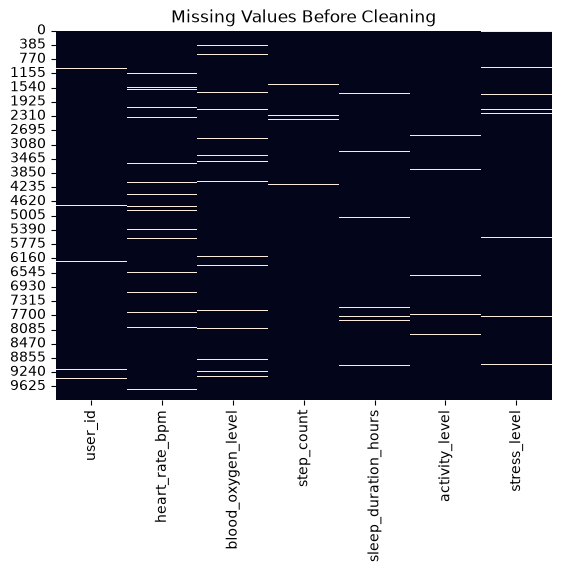

In [57]:

# Missing value count
print(df.isnull().sum())

# Missing value percentage
missing_percent = df.isnull().mean().mul(100).round(2)
print(missing_percent.sort_values(ascending=False))

# Visualize missing values
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values Before Cleaning")
plt.show()

Fill numeric missing values with the median and categorical missing values with the mode. This is a baseline strategy; use it only after confirming that the columns are correctly identified.

In [58]:

# Separate numerical and categorical columns
numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(include=["object", "category"]).columns

# Fill numeric missing values with median
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with mode
for col in categorical_cols:
    if df[col].mode().empty:
        continue
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

user_id                 0
heart_rate_bpm          0
blood_oxygen_level      0
step_count              0
sleep_duration_hours    0
activity_level          0
stress_level            0
dtype: int64


C:\Users\Admin\AppData\Local\Temp\ipykernel_6772\3757223337.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category"]).columns


## D. Clean invalid text values

Replace strings such as `ERROR`, empty strings, and common null markers with missing values before converting data types.

In [59]:

# Standardize text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Replace invalid/missing text markers
df = df.replace(
    ["ERROR", "error", "N/A", "NA", "null", "None", ""],
    np.nan
)
print(df.isnull().sum())

user_id                   0
heart_rate_bpm            0
blood_oxygen_level        0
step_count                0
sleep_duration_hours    397
activity_level            0
stress_level              0
dtype: int64


C:\Users\Admin\AppData\Local\Temp\ipykernel_6772\1646766887.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


## E. Convert numeric columns to numeric data types

Use this when a column is supposed to contain numbers but has text values such as `ERROR`.

In [60]:

# Replace invalid text with NaN in numeric fields
possible_numeric = [
    "heart_rate_bpm",
    "blood_oxygen_level",
    "step_count",
    "sleep_duration_hours"
]
for col in possible_numeric:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
print(df.dtypes)

user_id                 float64
heart_rate_bpm          float64
blood_oxygen_level      float64
step_count              float64
sleep_duration_hours    float64
activity_level              str
stress_level                str
dtype: object


## F. Standardize inconsistent categories

Your sample contains `Highly Active`, `Highly_Active`, and `Actve`. Normalize them only if they belong to the same category.

In [61]:

# Standardize category formatting
for col in df.select_dtypes(include="object").columns:
    df[col] = (
        df[col]
        .str.strip()
        .str.replace("_", " ", regex=False)
        .str.title()
    )

# Fix known activity-level spelling variations
if "activity_level" in df.columns:
    df["activity_level"] = df["activity_level"].replace({
        "Actve": "Active",
        "Highly Active": "Highly Active"
    })
print(df.select_dtypes(include="object").nunique())

activity_level     4
stress_level      11
dtype: int64


C:\Users\Admin\AppData\Local\Temp\ipykernel_6772\3267421903.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:
C:\Users\Admin\AppData\Local\Temp\ipykernel_6772\3267421903.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/m

If `activity_level` is numeric in the actual file, do not apply these category replacements to it. Confirm which column contains the activity labels first.

## G. Detect and investigate outliers

Use boxplots and the IQR method to flag possible outliers. The IQR method identifies unusual observations; it does not prove they are errors.

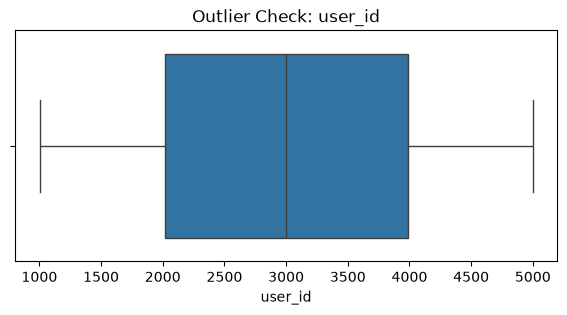

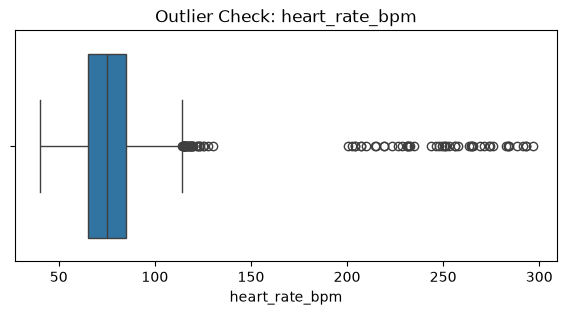

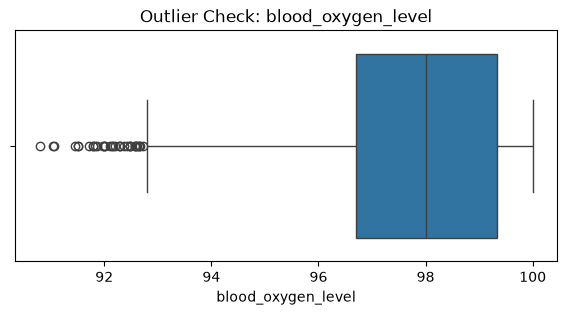

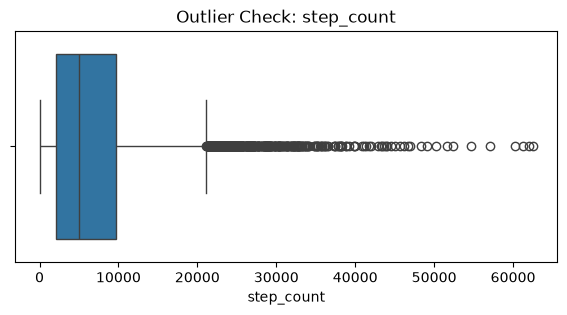

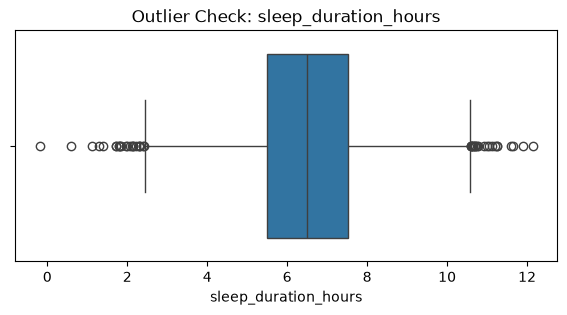

user_id Potential outliers: 0
heart_rate_bpm Potential outliers: 86
blood_oxygen_level Potential outliers: 35
step_count Potential outliers: 453
sleep_duration_hours Potential outliers: 45


In [62]:

numeric_cols = df.select_dtypes(include="number").columns

# Boxplots
for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Check: {col}")
    plt.show()

# IQR outlier counts
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(col, "Potential outliers:", count)

## H. Validate values using documented ranges

After confirming the correct headers and units, you can flag impossible or suspicious measurements. These example thresholds are screening rules, not medical diagnostic standards.

In [63]:

# Create flags instead of immediately deleting rows
if "heart_rate_bpm" in df.columns:
    df["heart_rate_flag"] = ~df["heart_rate_bpm"].between(30, 250)

if "blood_oxygen_level" in df.columns:
    df["blood_oxygen_flag"] = ~df["blood_oxygen_level"].between(0, 100)

if "step_count" in df.columns:
    df["step_count_flag"] = df["step_count"] < 0

if "sleep_duration_hours" in df.columns:
    df["sleep_duration_flag"] = ~df["sleep_duration_hours"].between(0, 24)

print(df.head())

   user_id  heart_rate_bpm  blood_oxygen_level    step_count  \
0   4174.0       58.939776           98.809650   5450.390578   
1   2998.0       75.220601           98.532195    727.601610   
2   1860.0      247.803052           97.052954   2826.521994   
3   2294.0       40.000000           96.894213  13797.338044   
4   2130.0       61.950165           98.583797  15679.067648   

   sleep_duration_hours activity_level stress_level  heart_rate_flag  \
0              7.167236  Highly Active            1            False   
1              6.538239  Highly Active            5            False   
2                   NaN  Highly Active            5            False   
3              7.367790         Active            3            False   
4                   NaN  Highly Active            6            False   

   blood_oxygen_flag  step_count_flag  sleep_duration_flag  
0              False            False                False  
1              False            False                False  

Do not use these rules to decide that a record is wrong until you confirm the meaning and units of each field. If the columns in the original file are mislabelled, fix the mapping before applying these checks.

# 5. Feature engineering and data modeling

Feature engineering means creating useful columns from existing data. A formal machine-learning model is not required for basic EDA. First create reliable analytical features and summary tables.

## A. Create useful features

Run this only after verifying the actual column names, meanings, units, and value ranges.

In [64]:

# Create a separate analytical DataFrame
analysis_df = df.copy()

# Activity categories, if activity_level is numeric
if "activity_level" in analysis_df.columns:
    if pd.api.types.is_numeric_dtype(analysis_df["activity_level"]):
        analysis_df["activity_band"] = pd.cut(
            analysis_df["activity_level"],
            bins=[-np.inf, 3, 7, np.inf],
            labels=["Low", "Medium", "High"]
        )

# Sleep categories, only if sleep is measured in hours
if "sleep_duration_hours" in analysis_df.columns:
    analysis_df["sleep_band"] = pd.cut(
        analysis_df["sleep_duration_hours"],
        bins=[-np.inf, 6, 9, np.inf],
        labels=["Short", "Typical Range", "Long"]
    )
print(analysis_df.head())

   user_id  heart_rate_bpm  blood_oxygen_level    step_count  \
0   4174.0       58.939776           98.809650   5450.390578   
1   2998.0       75.220601           98.532195    727.601610   
2   1860.0      247.803052           97.052954   2826.521994   
3   2294.0       40.000000           96.894213  13797.338044   
4   2130.0       61.950165           98.583797  15679.067648   

   sleep_duration_hours activity_level stress_level  heart_rate_flag  \
0              7.167236  Highly Active            1            False   
1              6.538239  Highly Active            5            False   
2                   NaN  Highly Active            5            False   
3              7.367790         Active            3            False   
4                   NaN  Highly Active            6            False   

   blood_oxygen_flag  step_count_flag  sleep_duration_flag     sleep_band  
0              False            False                False  Typical Range  
1              False          

These activity and sleep bands are illustrative analytical categories, not clinical classifications. Adjust them to the actual scale and project requirements.

## B. Create KPI summary tables

In [65]:

# Summary of numerical columns
kpi_summary = analysis_df.describe().T
kpi_summary["missing_values"] = analysis_df.isnull().sum()
kpi_summary["missing_percent"] = (
    analysis_df.isnull().mean() * 100).round(2)
display(kpi_summary)

# Activity category summary, if available
if "activity_band" in analysis_df.columns:
    display(
        analysis_df["activity_band"]
        .value_counts(dropna=False)
        .rename_axis("Activity Band")
        .reset_index(name="User Count")
    )

# Sleep category summary, if available
if "sleep_band" in analysis_df.columns:
    display(
        analysis_df["sleep_band"]
        .value_counts(dropna=False)
        .rename_axis("Sleep Band")
        .reset_index(name="User Count")
    )

,count,mean,std,min,25%,50%,75%,max,missing_values,missing_percent
user_id,10000.0,3007.289700,1138.959109,1001.000000,2016.000000,2998.000000,3985.000000,4999.000000,0,0.00
heart_rate_bpm,10000.0,76.002867,19.020902,40.000000,65.322796,75.220601,84.791711,296.593970,0,0.00
blood_oxygen_level,10000.0,97.846653,1.706913,90.791208,96.703718,98.010642,99.327856,100.000000,0,0.00
step_count,10000.0,6965.454372,6854.247583,0.910138,2037.300857,4962.534599,9680.097095,62486.690753,0,0.00
sleep_duration_hours,9603.0,6.505463,1.510029,-0.194453,5.493820,6.503308,7.529357,12.140233,397,3.97


,Sleep Band,User Count
0,Typical Range,5500
1,Short,3596
2,Long,507
3,NaN,397


## C. Grouped analysis

This is useful for answering questions such as average heart rate by activity group or average sleep duration by stress level.

In [66]:

# Average numeric metrics by activity level
if "activity_level" in analysis_df.columns:
    display(
        analysis_df.groupby("activity_level", dropna=False)
        .mean(numeric_only=True)
        .reset_index()
    )

# Average numeric metrics by stress level
if "stress_level" in analysis_df.columns:
    display(
        analysis_df.groupby("stress_level", dropna=False)
        .mean(numeric_only=True)
        .reset_index()
    )

,activity_level,user_id,heart_rate_bpm,blood_oxygen_level,step_count,sleep_duration_hours,heart_rate_flag,blood_oxygen_flag,step_count_flag,sleep_duration_flag
0,Active,3017.573966,75.939678,97.815601,7016.726770,6.519935,0.001225,0.0,0.0,0.041348
1,Highly Active,3000.925671,76.056208,97.839185,6927.962264,6.502024,0.003123,0.0,0.0,0.039663
2,Seddentary,3041.463220,75.684632,97.847018,6978.921263,6.500253,0.002665,0.0,0.0,0.038913
3,Sedentary,2960.633072,76.384597,97.921857,6921.629063,6.489583,0.004225,0.0,0.0,0.038021


,stress_level,user_id,heart_rate_bpm,blood_oxygen_level,step_count,sleep_duration_hours,heart_rate_flag,blood_oxygen_flag,step_count_flag,sleep_duration_flag
0,1,2964.566057,76.526550,97.918791,6819.459055,6.544879,0.005081,0.0,0.0,0.036585
1,10,2979.470650,75.968012,97.854817,7273.698910,6.554654,0.002096,0.0,0.0,0.041929
2,2,2998.615576,75.684604,97.920768,6786.373297,6.530285,0.001657,0.0,0.0,0.036454
3,3,2961.871357,75.874786,97.832983,6982.843391,6.483722,0.004020,0.0,0.0,0.042211
4,4,3040.785714,76.677547,97.792774,7325.314331,6.428832,0.002070,0.0,0.0,0.030021
5,5,3021.228571,75.532901,97.741386,6821.954199,6.517283,0.001058,0.0,0.0,0.033862
6,6,3025.609391,76.561964,97.869820,7146.790311,6.495143,0.002997,0.0,0.0,0.040959
7,7,3085.375746,75.965468,97.829700,6967.605892,6.523756,0.002982,0.0,0.0,0.045726
8,8,3001.483097,75.554009,97.831027,6651.994676,6.474043,0.001091,0.0,0.0,0.039258
9,9,2997.279713,75.769001,97.851587,6857.903454,6.512552,0.003074,0.0,0.0,0.051230


Data modeling note: If each row represents one user, check whether `User ID` is unique. If users have repeated measurements, a better model may separate a user table from a measurement table using `User ID` as the key. Do not aggregate repeated measurements without deciding whether you want per-user or per-measurement metrics.

# 6. Data visualization — complete chart collection

The following charts cover distributions, categories, relationships, comparisons, and data quality.

## A. Histograms for numerical columns

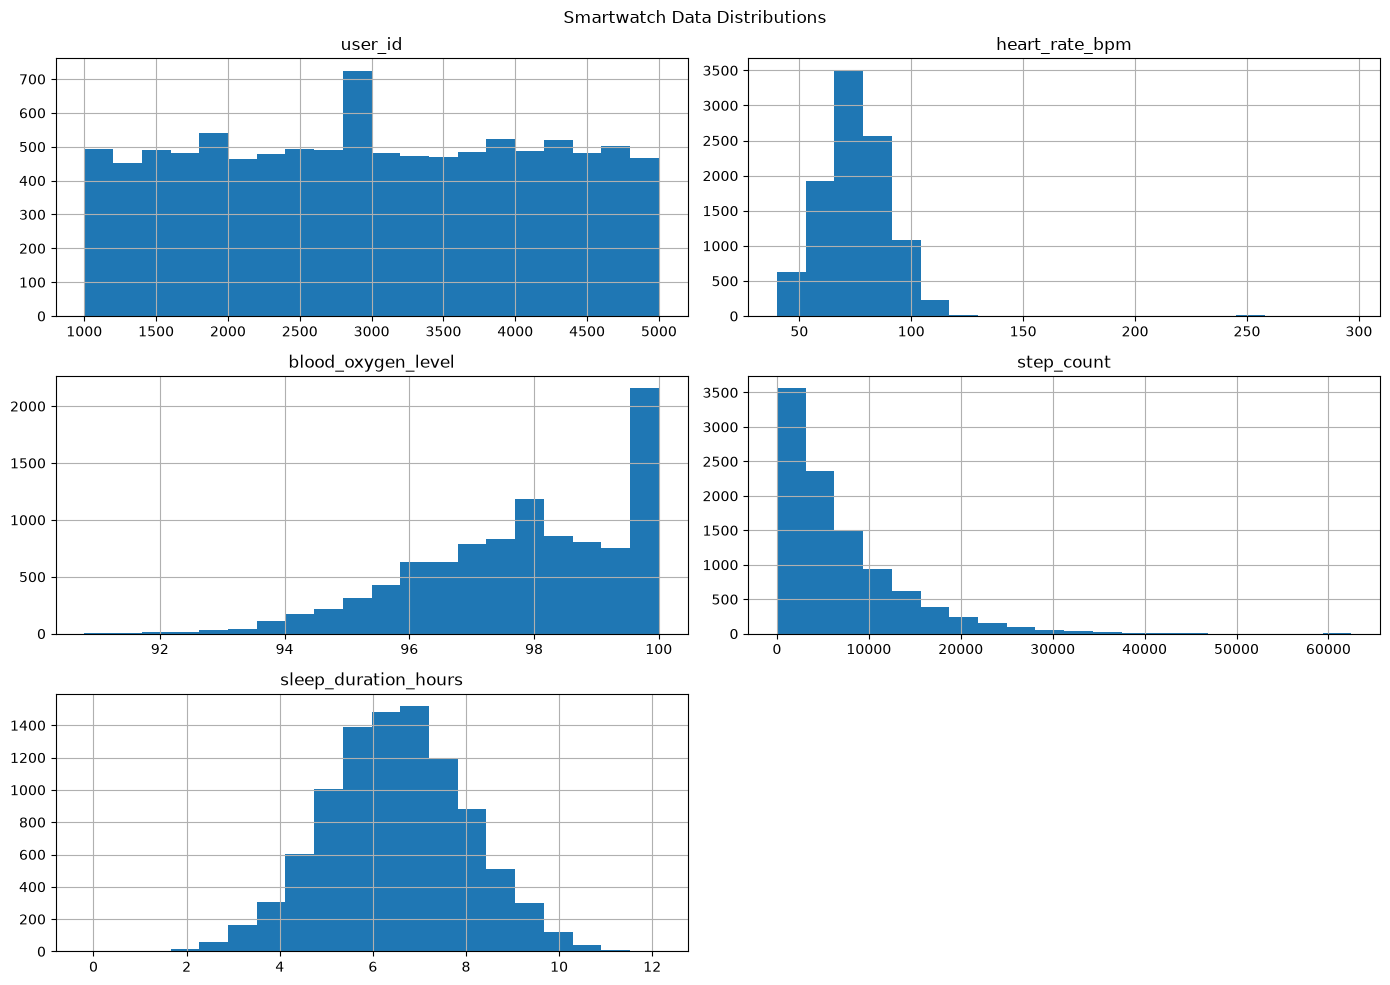

In [67]:

numeric_cols = analysis_df.select_dtypes(include="number").columns
analysis_df[numeric_cols].hist(
    figsize=(14, 10),
    bins=20)
plt.suptitle("Smartwatch Data Distributions")
plt.tight_layout()
plt.show()

## B. Count plots for categorical columns

C:\Users\Admin\AppData\Local\Temp\ipykernel_6772\1506776818.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = analysis_df.select_dtypes(


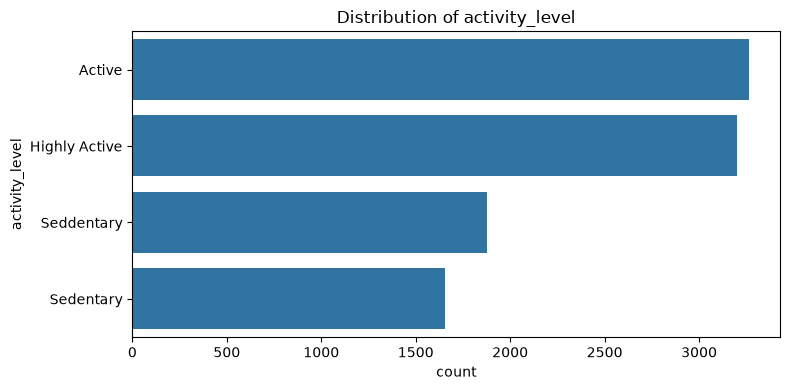

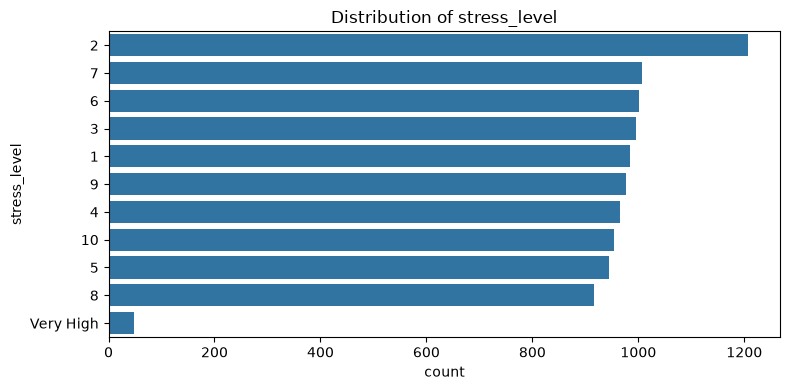

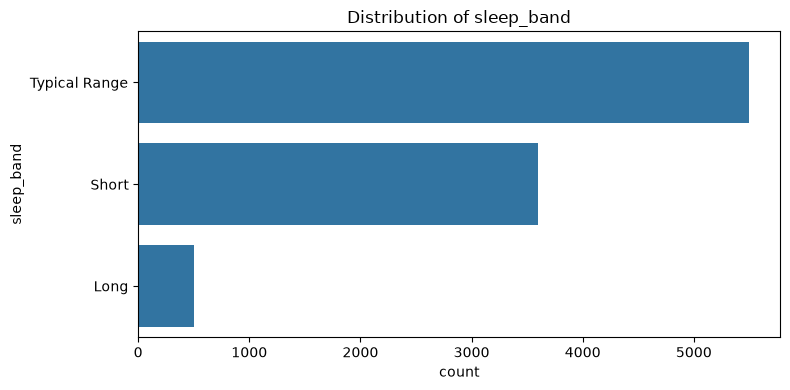

In [68]:

categorical_cols = analysis_df.select_dtypes(
    include=["object", "category"]).columns
for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(
        data=analysis_df,
        y=col,
        order=analysis_df[col].value_counts().index[:15]
    )
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

## C. Correlation heatmap

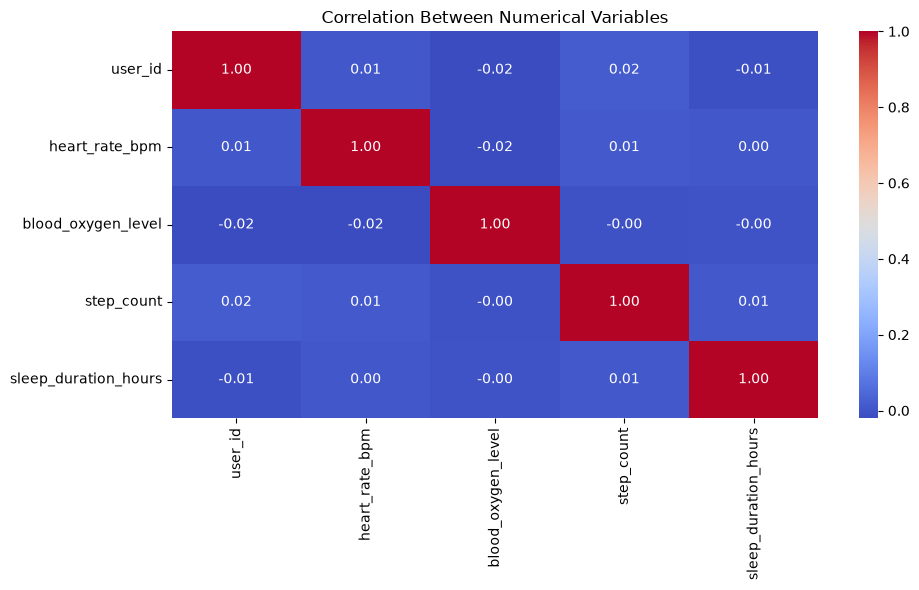

In [69]:

numeric_df = analysis_df.select_dtypes(include="number")
if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        fmt=".2f",
        cmap="coolwarm"
    )
    plt.title("Correlation Between Numerical Variables")
    plt.tight_layout()
    plt.show()

## D. Scatter plots

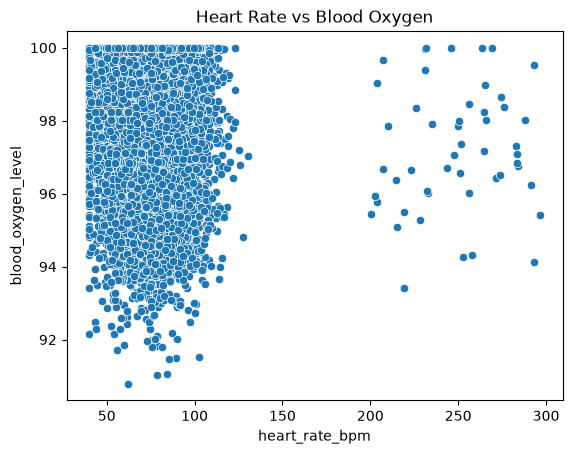

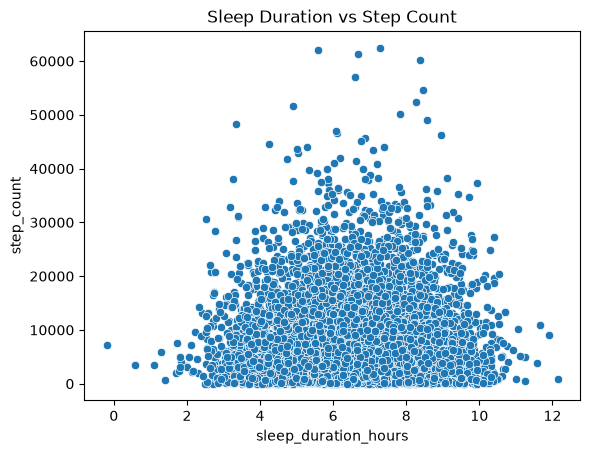

In [70]:

# Compare heart rate and blood oxygen
if {
    "heart_rate_bpm",
    "blood_oxygen_level"}.issubset(analysis_df.columns):
    sns.scatterplot(
        data=analysis_df,
        x="heart_rate_bpm",
        y="blood_oxygen_level"
    )
    plt.title("Heart Rate vs Blood Oxygen")
    plt.show()

# Compare sleep duration and step count
if {
    "sleep_duration_hours",
    "step_count"}.issubset(analysis_df.columns):
    sns.scatterplot(
        data=analysis_df,
        x="sleep_duration_hours",
        y="step_count"
    )
    plt.title("Sleep Duration vs Step Count")
    plt.show()

## E. Compare numerical metrics by category

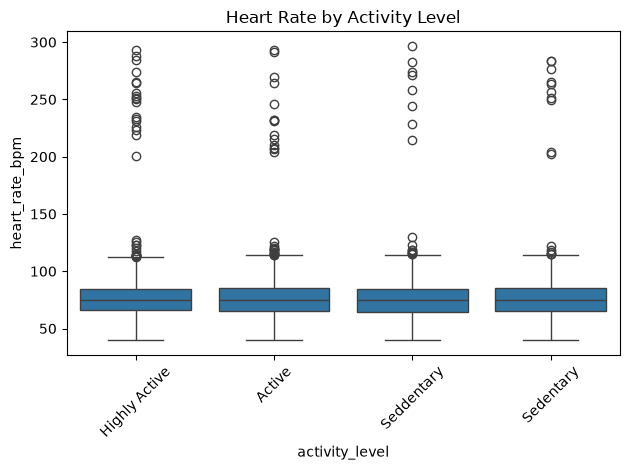

In [71]:

if {
    "activity_level",
    "heart_rate_bpm"}.issubset(analysis_df.columns):
    sns.boxplot(
        data=analysis_df,
        x="activity_level",
        y="heart_rate_bpm"
    )
    plt.title("Heart Rate by Activity Level")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

If `activity_level` is continuous rather than categorical, use a scatter plot instead of a boxplot, or group the values into meaningful bands.

## F. Missing-value comparison

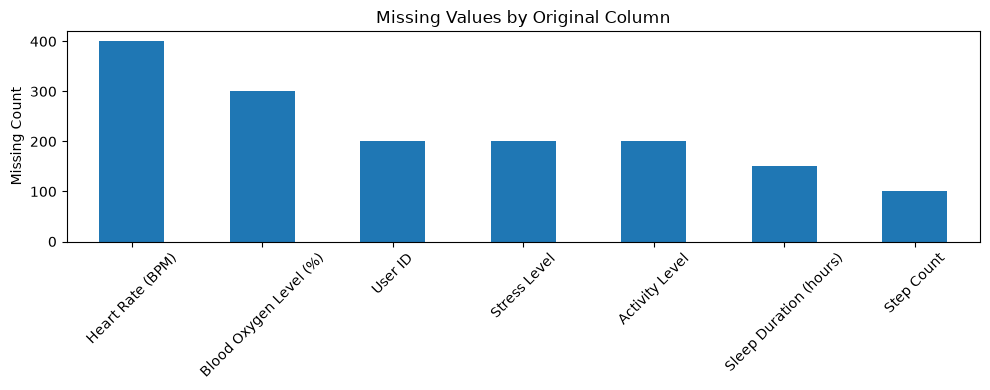

In [72]:

missing = df_original.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if not missing.empty:
    missing.plot(kind="bar", figsize=(10, 4))
    plt.title("Missing Values by Original Column")
    plt.ylabel("Missing Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the original dataset.")

# 7. Final data-quality report

This report helps you compare the original dataset with the cleaned dataset.

In [73]:

print("ORIGINAL DATA")
print("Shape:", df_original.shape)
print("Missing values:", df_original.isnull().sum().sum())
print("Duplicate rows:", df_original.duplicated().sum())

print("CURRENT DATA")
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("Current data types:")
print(df.dtypes)

print("Current missing values:")
print(df.isnull().sum())

ORIGINAL DATA
Shape: (10000, 7)
Missing values: 1551
Duplicate rows: 0
CURRENT DATA
Shape: (10000, 11)
Missing values: 397
Duplicate rows: 0
Current data types:
user_id                 float64
heart_rate_bpm          float64
blood_oxygen_level      float64
step_count              float64
sleep_duration_hours    float64
activity_level              str
stress_level                str
heart_rate_flag            bool
blood_oxygen_flag          bool
step_count_flag            bool
sleep_duration_flag        bool
dtype: object
Current missing values:
user_id                   0
heart_rate_bpm            0
blood_oxygen_level        0
step_count                0
sleep_duration_hours    397
activity_level            0
stress_level              0
heart_rate_flag           0
blood_oxygen_flag         0
step_count_flag           0
sleep_duration_flag       0
dtype: int64


Note that `df` in this workflow is the working copy, not necessarily fully cleaned yet. In particular, invalid strings should be replaced with missing values before filling missing values. After conversion with `pd.to_numeric(errors="coerce")`, check for new missing values and handle them again if appropriate.

# 8. Export your results

In [74]:

# Save working dataset
df.to_csv("smartwatch_cleaned.csv", index=False)

# Save analytical features
analysis_df.to_csv("smartwatch_analysis.csv", index=False)

# Save missing-value report
missing_report = pd.DataFrame({
    "Column": df_original.columns,
    "Missing Count": df_original.isnull().sum().values,
    "Missing Percentage": (
        df_original.isnull().mean().values * 100
    ).round(2)
})
missing_report.to_csv("missing_values_report.csv", index=False)
print("Files saved successfully!")

Files saved successfully!


## 9. Suggested project deliverables

| Deliverable                 | Purpose                                        |
| --------------------------- | ---------------------------------------------- |
| `smartwatch_cleaned.csv`    | Working dataset after cleaning                 |
| `smartwatch_analysis.csv`   | Dataset with derived analytical features       |
| `missing_values_report.csv` | Missing-value assessment                       |
| EDA charts                  | Distribution, correlation and outlier analysis |
| KPI summary                 | Descriptive statistics and grouped comparisons |

Before you trust the results: print `df.columns.tolist()` and `df.head(10).to_string()` to verify the apparent header mismatch in your sample. The code above deliberately avoids automatically deleting unusual measurements or assuming that every field's current name and units are correct. Fixing that mapping is the most important step before building meaningful health analytics or a predictive model.